# Machine Learning & AI – Major Capstone Project

## Bank Loan Approval Prediction Using Machine Learning

### Project Overview
This project aims to predict whether a bank loan application will be approved or rejected using machine learning techniques.

### Objective
To build a classification model using Random Forest that analyzes applicant information such as income, education, marital status, credit history, and property area to predict loan approval.

### Dataset
Kaggle – Loan Prediction Dataset

### Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Joblib

### Machine Learning Algorithm
Random Forest Classifier

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

## Step 1: Data Loading and Exploration

The loan prediction dataset is loaded using Pandas. Basic statistical information and missing values are examined to understand the structure and quality of the dataset.

In [3]:
df = pd.read_csv("loan_prediction.csv")

print("Dataset Loaded Successfully!")

display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Loaded Successfully!


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB

Statistical Summary:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000



Missing Values:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


## Step 2: Data Cleaning and Preprocessing

Data preprocessing is performed to prepare the dataset for machine learning.

- Loan_ID is removed because it is an identification column.
- Missing numerical values are filled using median imputation.
- Missing categorical values are filled using most frequent value imputation.
- Categorical features are converted into numerical format using OneHotEncoder.

In [4]:
# Remove unnecessary ID column
df.drop(columns=['Loan_ID'], inplace=True, errors='ignore')

# Remove rows with missing target values
df.dropna(subset=['Loan_Status'], inplace=True)

# Encode target variable
df['Loan_Status'] = df['Loan_Status'].map({
    'Y': 1,
    'N': 0
})

# Separate features and target
X = df.drop('Loan_Status', axis=1)
y = df['Loan_Status']

print("Data Cleaning Completed!")
print("Features:", X.shape)
print("Target:", y.shape)

Data Cleaning Completed!
Features: (614, 11)
Target: (614,)


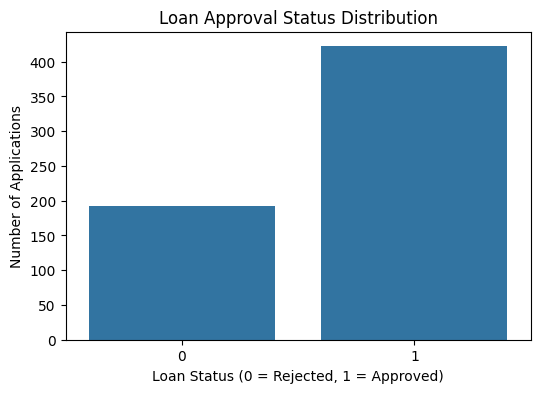

In [5]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Loan_Status')

plt.title("Loan Approval Status Distribution")
plt.xlabel("Loan Status (0 = Rejected, 1 = Approved)")
plt.ylabel("Number of Applications")

plt.show()

## Step 3: Model Training Using Random Forest

Random Forest is a supervised machine learning algorithm that combines multiple decision trees to make predictions.

The dataset is divided into training and testing sets. Numerical and categorical features are preprocessed separately before training the Random Forest classifier.

In [6]:
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

# Numerical preprocessing
numeric_transformer = SimpleImputer(strategy='median')

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Create complete ML pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ))
])

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train model
model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

C:\Users\prana\AppData\Local\Temp\ipykernel_28760\2375783526.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


Random Forest Model Trained Successfully!


## Step 4: Model Evaluation

The trained model is evaluated using the following performance metrics:

- Accuracy: Measures overall prediction correctness.
- Precision: Measures how many predicted approvals were actually approved.
- Recall: Measures how many actual approved applications were correctly identified.
- F1 Score: Balances precision and recall.

A confusion matrix is also generated to visualize correct and incorrect predictions.

In [7]:
# Make predictions
y_pred = model.predict(X_test)

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Model Evaluation Results")
print("------------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Evaluation Results
------------------------
Accuracy: 0.8211382113821138
Precision: 0.8387096774193549
Recall: 0.9176470588235294
F1 Score: 0.8764044943820225

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.61      0.68        38
           1       0.84      0.92      0.88        85

    accuracy                           0.82       123
   macro avg       0.80      0.76      0.78       123
weighted avg       0.82      0.82      0.81       123



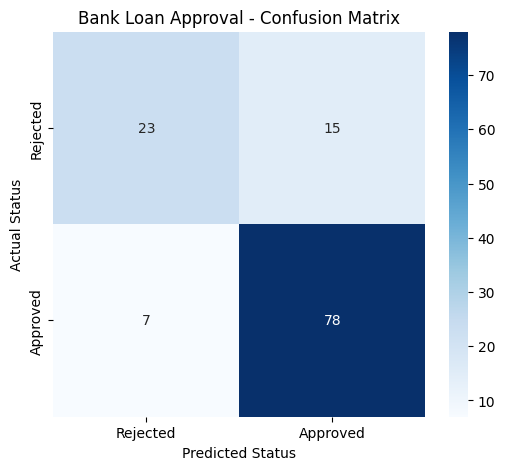

In [8]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Rejected', 'Approved'],
    yticklabels=['Rejected', 'Approved']
)

plt.title("Bank Loan Approval - Confusion Matrix")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")

plt.show()

## Step 5: Loan Approval Prediction

The trained model is used to predict the approval status of a new loan application based on applicant details.

The model returns whether the loan application is likely to be approved or rejected.

In [9]:
# Sample new loan application
new_applicant = pd.DataFrame([{
    'Gender': 'Male',
    'Married': 'Yes',
    'Dependents': '0',
    'Education': 'Graduate',
    'Self_Employed': 'No',
    'ApplicantIncome': 5000,
    'CoapplicantIncome': 2000,
    'LoanAmount': 150,
    'Loan_Amount_Term': 360,
    'Credit_History': 1.0,
    'Property_Area': 'Urban'
}])

# Predict
prediction = model.predict(new_applicant)

if prediction[0] == 1:
    print("Loan Application: Approved")
else:
    print("Loan Application: Rejected")

Loan Application: Approved


In [10]:
# Save trained model
joblib.dump(model, 'loan_approval_model.pkl')

print("Model Saved Successfully!")

# Load trained model
loaded_model = joblib.load('loan_approval_model.pkl')

# Test loaded model
loaded_prediction = loaded_model.predict(X_test)

print("Loaded Model Accuracy:",
      accuracy_score(y_test, loaded_prediction))

Model Saved Successfully!
Loaded Model Accuracy: 0.8211382113821138


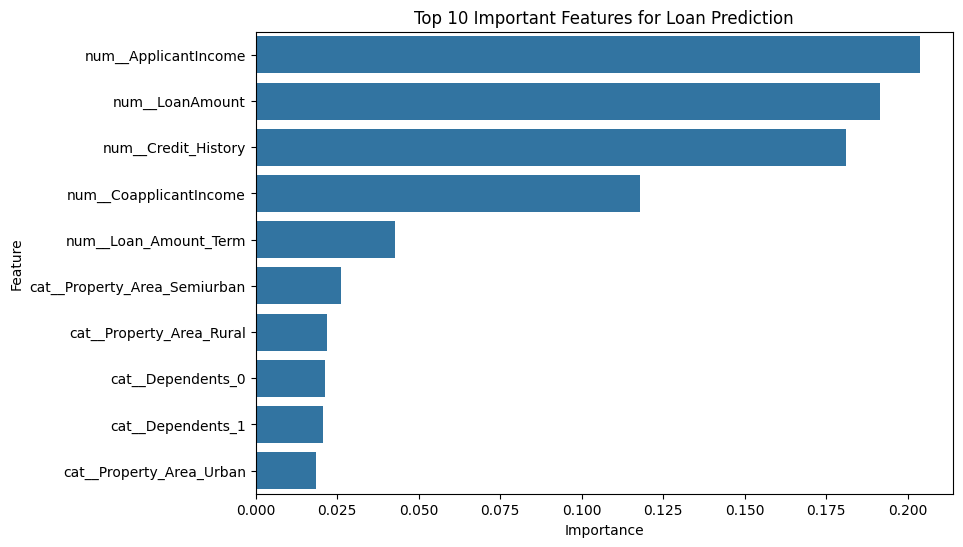

In [11]:
# Extract trained Random Forest
rf_model = loaded_model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = loaded_model.named_steps[
    'preprocessor'
].get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).head(10)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Important Features for Loan Prediction")
plt.show()

## Conclusion

The Bank Loan Approval Prediction project was successfully developed using the Random Forest classification algorithm.

The project involved:
- Loading and exploring the loan prediction dataset.
- Handling missing numerical and categorical values.
- Applying One-Hot Encoding to categorical features.
- Training a Random Forest classification model.
- Evaluating performance using Accuracy, Precision, Recall, and F1 Score.
- Visualizing the confusion matrix and feature importance.
- Predicting new loan applications.
- Saving and loading the trained model using Joblib.

This project demonstrates the practical application of machine learning in financial data analysis and loan approval prediction.